# TWFE Diagnostic: Jakiela Weights and Slope Test
This notebook performs a diagnostic analysis of Two-Way Fixed Effects (TWFE) models, focusing on the identification of potential biases due to negative weights and heterogeneous treatment effects using the Jakiela (2021) methodology.

## 1. Setup and Library Imports
We initialize the environment, enable autoreload for local modules, and import the necessary libraries for data manipulation, statistical testing, and plotting.
**Note:** For this to work on GitHub, the `twfe_tools` folder must be in the same directory as this notebook.

In [6]:
%load_ext autoreload
%autoreload 2

import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
# Silencia advertencias de futuras versiones y de datos faltantes en modelos
warnings.filterwarnings('ignore', category=FutureWarning)
from linearmodels.shared.exceptions import MissingValueWarning
warnings.filterwarnings('ignore', category=MissingValueWarning)



# --- SMART PATH LOGIC ---
current_dir = os.getcwd()
if "twfe_diagnostics" in current_dir:
    project_root = current_dir.split("twfe_diagnostics")[0] + "twfe_diagnostics"
else:
    project_root = os.path.join(current_dir, "twfe_diagnostics")

if project_root not in sys.path:
    sys.path.append(project_root)

# --- IMPORTING TOOLS ---
try:
    from twfe_tools.weights import get_jakiela_weights, get_weight_summary
    from twfe_tools.plotting import plot_weights_histogram
    # IMPORTAMOS LA CLASE QUE RESTAURASTE
    from twfe_tools.diagnostics import TWFEDiagnostic
    
    print(f"✅ TWFEDiagnostic class loaded from: {project_root}")
except Exception as e:
    print(f"❌ Import Error: {e}")
    print("TIP: Restart the kernel if the error persists after saving diagnostics.py")

print("✅ Environment ready!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
✅ TWFEDiagnostic class loaded from: c:\Users\andre\Downloads\twfe_diagnostics
✅ Environment ready!


# 2. Load your data 


In [7]:
# Portable data path
path_data = os.path.join(project_root, "data", "WDI-FPE-data.dta")

if os.path.exists(path_data):
    df = pd.read_stata(path_data)
    print(f"✅ Data loaded. Observations: {len(df)}")
else:
    print(f"❌ File not found at {path_data}")

✅ Data loaded. Observations: 525


# 3. Compute weights

--- Weight Summary ---
Total Observations    5.250000e+02
Positive Weights      2.740000e+02
Negative Weights      2.510000e+02
Mean Weight           1.149874e-17
Min Weight           -2.334796e-02
Max Weight            2.237259e-02
Sum of Weights        6.036838e-15
dtype: float64


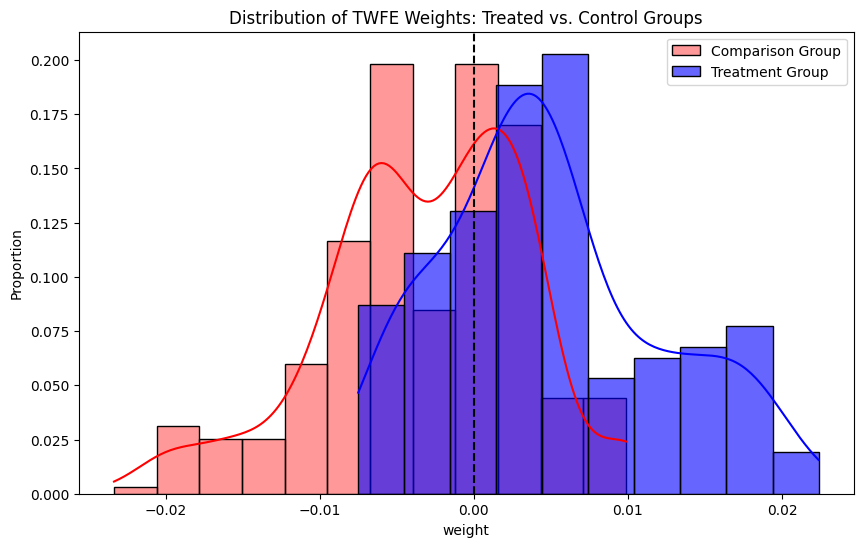


--- Jakiela Slope Test ---
                            OLS Regression Results                            
Dep. Variable:           outcome_diff   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     17.10
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           4.23e-05
Time:                        18:05:24   Log-Likelihood:                -1374.3
No. Observations:                 454   AIC:                             2753.
Df Residuals:                     452   BIC:                             2761.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2129   

In [8]:
# 1. Calculate Jakiela Weights
df['weight'] = get_jakiela_weights(df, 'treatment', 'id', 'year')

# 2. Numerical Summary
print("--- Weight Summary ---")
print(get_weight_summary(df))

# 3. Visual Diagnostic (Histogram)
plot_weights_histogram(df)

# 4. Statistical Test (using the TWFEDiagnostic Class)
print("\n--- Jakiela Slope Test ---")
# Initialize the diagnostic object
diag = TWFEDiagnostic(df, y_col='primary', d_col='treatment', unit_col='id', time_col='year')

# Run the slope test method from the class
print(diag.run_slope_test())

## 4. Comparison: TWFE vs. CSDID
In this section, we compare the standard Two-Way Fixed Effects estimate against the **Callaway & Sant’Anna (2021)** approach. TWFE can be biased when treatment timing is staggered; CSDID corrects this by using only "clean" control groups.

In [9]:
# 1. Estimate Robust TWFE (Traditional Approach)
print("Estimating Robust TWFE...")
res_twfe = diag.run_robust_comparison()
twfe_val = res_twfe.params[0]

# 2. Estimate Simplified CSDID (Clean Approach)
print("Estimating Simplified CSDID (Callaway & Sant'Anna logic)...")
att_results = diag.run_csdid_simple()
csdid_val = att_results['att'].mean()

# 3. Calculate Percentage Difference (Bias Diagnostic)
if twfe_val != 0:
    diff = abs(twfe_val - csdid_val) / abs(twfe_val) * 100
else:
    diff = 0

# 4. Output Diagnostic Report
print("-" * 40)
print(f"DIAGNOSTIC RESULTS:")
print(f"TWFE Estimate:  {twfe_val:.4f}")
print(f"CSDID Estimate: {csdid_val:.4f}")
print(f"Relative Gap:   {diff:.2f}%")
print("-" * 40)

if diff > 10:
    print("🚨 STATUS: HIGH BIAS RISK")
    print("The results suggest that staggered adoption timing and negative weights")
    print("are creating a significant wedge between TWFE and the clean ATT.")
    print("Recommendation: Use CSDID (Callaway & Sant'Anna) estimates for your paper.")
else:
    print("✅ STATUS: ESTIMATES ARE ROBUST")
    print("The small difference between estimators suggests that the bias from")
    print("staggered adoption is not a major concern in this specific dataset.")

Estimating Robust TWFE...
Estimating Simplified CSDID (Callaway & Sant'Anna logic)...
----------------------------------------
DIAGNOSTIC RESULTS:
TWFE Estimate:  20.4282
CSDID Estimate: 11.0252
Relative Gap:   46.03%
----------------------------------------
🚨 STATUS: HIGH BIAS RISK
The results suggest that staggered adoption timing and negative weights
are creating a significant wedge between TWFE and the clean ATT.
Recommendation: Use CSDID (Callaway & Sant'Anna) estimates for your paper.
